In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import (
    SelectKBest,
    mutual_info_classif,
    RFECV
)
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import mutual_info_classif

from matplotlib.ticker import FuncFormatter

In [2]:
ds1_features = pd.read_csv("../src/ds1_features.csv")
ds2_features = pd.read_csv("../src/ds2_features.csv")

print("DS1:", ds1_features.shape)
print("DS2:", ds2_features.shape)

display(ds1_features.head())

DS1: (57549, 32)
DS2: (51902, 32)


,record_id,annotation_sample,type,class,anomaly,lead,mean,std,min,max,...,amp_m40,amp_p0,amp_p40,amp_p80,qrs_min,qrs_max,qrs_peak_to_peak,rr_prev,rr_local_median,rr_prev_relative
0,101,396,N,N,0,MLII,-0.007224,0.184017,-0.154579,1.155915,...,-0.050517,1.155915,-0.080622,-0.144992,-0.154579,1.155915,1.310494,0.869444,NaN,NaN
1,101,711,N,N,0,MLII,0.019965,0.205471,-0.136370,1.307746,...,-0.025237,1.307746,-0.035249,-0.135330,-0.136370,1.307746,1.444115,0.875000,NaN,NaN
2,101,1032,N,N,0,MLII,0.013908,0.212843,-0.152129,1.332405,...,-0.063754,1.332405,-0.023320,-0.138580,-0.152129,1.332405,1.484534,0.891667,NaN,NaN
3,101,1368,N,N,0,MLII,-0.002989,0.216853,-0.171472,1.346058,...,-0.070502,1.346058,-0.068617,-0.170820,-0.171472,1.346058,1.517530,0.933333,NaN,NaN
4,101,1712,N,N,0,MLII,0.017791,0.201842,-0.160678,1.242805,...,-0.022165,1.238702,-0.060934,-0.140492,-0.155989,1.242805,1.398794,0.955556,NaN,NaN


In [3]:
metadata_columns = [
    "record_id",
    "annotation_sample",
    "type",
    "class",
    "anomaly",
    "lead"
]

feature_columns = [
    col for col in ds1_features.select_dtypes(
        include="number"
    ).columns
    if col not in metadata_columns
]

assert set(feature_columns).issubset(ds2_features.columns)

print("Liczba cech:", len(feature_columns))
print("\nLista cech:")
print(*feature_columns, sep="\n")

Liczba cech: 26

Lista cech:
mean
std
min
max
peak_to_peak
median
iqr
skew
kurtosis
max_abs
rms
waveform_length
max_diff
qrs_abs_area
qrs_max_slope
amp_m80
amp_m40
amp_p0
amp_p40
amp_p80
qrs_min
qrs_max
qrs_peak_to_peak
rr_prev
rr_local_median
rr_prev_relative


In [4]:
# Kontrola brakujących wartości i zmienności cech
quality = pd.DataFrame({
    "Braki DS1": ds1_features[feature_columns].isna().sum(),
    "Braki DS2": ds2_features[feature_columns].isna().sum(),
    "Liczba unikalnych wartości": ds1_features[feature_columns].nunique(),
    "Odchylenie standardowe": ds1_features[feature_columns].std()
})

display(quality)

# Cechy stałe
constant_features = quality.index[
    quality["Liczba unikalnych wartości"] <= 1
].tolist()

print("Cechy stałe:", constant_features)

# Rozkład klas w DS1
print("\nLiczebności klas DS1:")
display(ds1_features["class"].value_counts())

# Kontrola liczby rekordów
print("\nLiczba rekordów DS1:",
      ds1_features["record_id"].nunique())

,Braki DS1,Braki DS2,Liczba unikalnych wartości,Odchylenie standardowe
mean,0,0,57549,0.032718
std,0,0,57549,0.139456
min,0,0,56629,0.370754
max,0,0,57257,0.634972
peak_to_peak,0,0,57411,0.750599
median,0,0,57528,0.054081
iqr,0,0,57549,0.139026
skew,0,0,57549,1.642473
kurtosis,0,0,57549,6.785164
max_abs,0,0,57279,0.603115


Cechy stałe: []

Liczebności klas DS1:


class
N    48168
Q     4154
V     3813
S      999
F      415
Name: count, dtype: int64


Liczba rekordów DS1: 25


In [5]:
# Macierz bezwzględnych korelacji
corr_matrix = ds1_features[feature_columns].corr().abs()

thresholds = [0.85, 0.90, 0.95]
correlation_results = {}

for threshold in thresholds:
    upper = corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )

    to_drop = [
        col for col in upper.columns
        if (upper[col] > threshold).any()
    ]

    selected = [
        col for col in feature_columns
        if col not in to_drop
    ]

    correlation_results[threshold] = selected

    print(f"\nPróg korelacji: {threshold:.2f}")
    print(f"Liczba zachowanych cech: {len(selected)}")
    print(f"Usunięte cechy: {to_drop}")



Próg korelacji: 0.85
Liczba zachowanych cech: 16
Usunięte cechy: ['peak_to_peak', 'max_abs', 'rms', 'waveform_length', 'qrs_abs_area', 'qrs_max_slope', 'amp_p0', 'qrs_min', 'qrs_max', 'qrs_peak_to_peak']

Próg korelacji: 0.90
Liczba zachowanych cech: 20
Usunięte cechy: ['max_abs', 'rms', 'qrs_max_slope', 'qrs_min', 'qrs_max', 'qrs_peak_to_peak']

Próg korelacji: 0.95
Liczba zachowanych cech: 20
Usunięte cechy: ['max_abs', 'rms', 'qrs_max_slope', 'qrs_min', 'qrs_max', 'qrs_peak_to_peak']


In [7]:
X = ds1_features[feature_columns].copy()

# Uzupełnienie braków medianą z DS1
X = X.fillna(X.median())

mi_results = pd.DataFrame(index=feature_columns)

for target in ["class", "anomaly"]:
    scores = mutual_info_classif(
        X,
        ds1_features[target],
        random_state=42
    )

    mi_results[target] = scores

mi_results = mi_results.sort_values(
    by="class",
    ascending=False
)

display(mi_results.round(4))

,class,anomaly
rr_prev_relative,0.2485,0.1671
rr_prev,0.2307,0.1225
amp_p40,0.2258,0.1391
rr_local_median,0.2200,0.1080
kurtosis,0.2009,0.1312
amp_p0,0.1717,0.0981
qrs_max,0.1654,0.0912
std,0.1606,0.0690
rms,0.1593,0.0703
qrs_abs_area,0.1522,0.0690


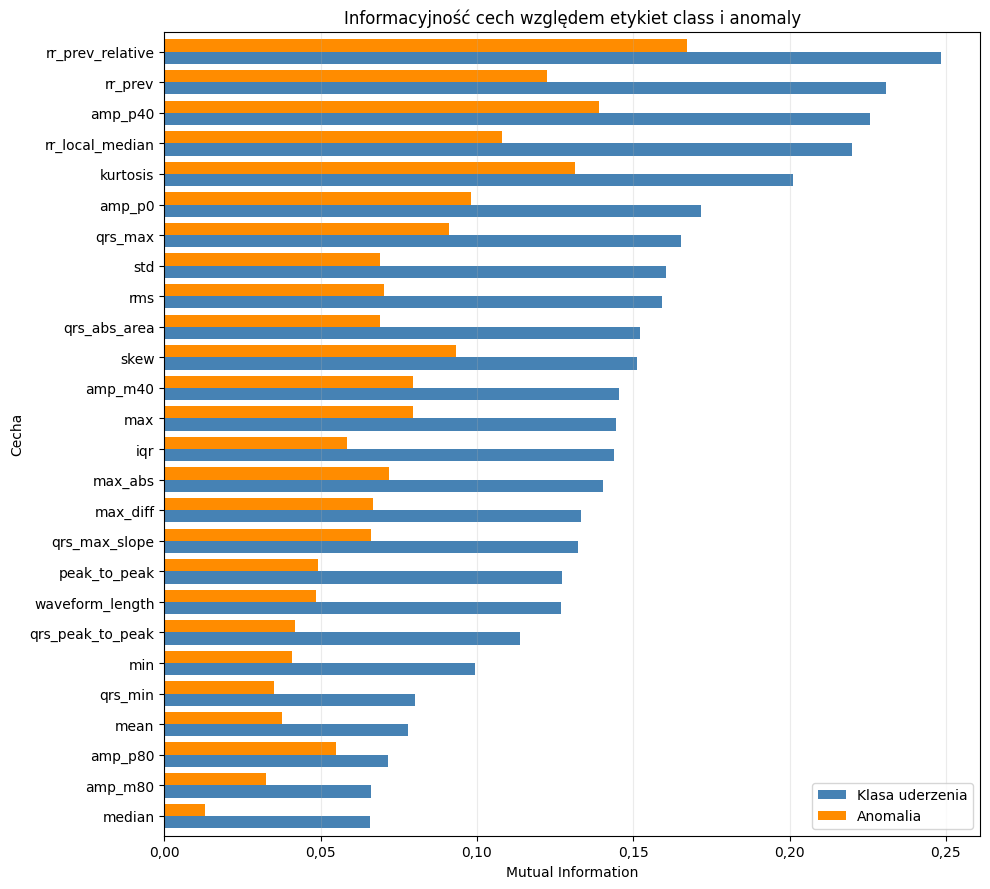

In [8]:
fig, ax = plt.subplots(figsize=(10, 9))

mi_results.sort_values("class").plot(
    kind="barh",
    ax=ax,
    width=0.8,
    color=["steelblue", "darkorange"]
)

ax.set_title(
    "Informacyjność cech względem etykiet class i anomaly"
)
ax.set_xlabel("Mutual Information")
ax.set_ylabel("Cecha")

ax.xaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f"{x:.2f}".replace(".", ",")
    )
)

ax.legend(["Klasa uderzenia", "Anomalia"])
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

In [9]:
k_values = [8, 12, 16, 20]

mi_selected_features = {}

for target in ["class", "anomaly"]:
    ranking = mi_results[target].sort_values(
        ascending=False
    ).index.tolist()

    for k in k_values:
        selected = ranking[:k]
        mi_selected_features[(target, k)] = selected

        print(f"\nEtykieta: {target}, k={k}")
        print(", ".join(selected))


Etykieta: class, k=8
rr_prev_relative, rr_prev, amp_p40, rr_local_median, kurtosis, amp_p0, qrs_max, std

Etykieta: class, k=12
rr_prev_relative, rr_prev, amp_p40, rr_local_median, kurtosis, amp_p0, qrs_max, std, rms, qrs_abs_area, skew, amp_m40

Etykieta: class, k=16
rr_prev_relative, rr_prev, amp_p40, rr_local_median, kurtosis, amp_p0, qrs_max, std, rms, qrs_abs_area, skew, amp_m40, max, iqr, max_abs, max_diff

Etykieta: class, k=20
rr_prev_relative, rr_prev, amp_p40, rr_local_median, kurtosis, amp_p0, qrs_max, std, rms, qrs_abs_area, skew, amp_m40, max, iqr, max_abs, max_diff, qrs_max_slope, peak_to_peak, waveform_length, qrs_peak_to_peak

Etykieta: anomaly, k=8
rr_prev_relative, amp_p40, kurtosis, rr_prev, rr_local_median, amp_p0, skew, qrs_max

Etykieta: anomaly, k=12
rr_prev_relative, amp_p40, kurtosis, rr_prev, rr_local_median, amp_p0, skew, qrs_max, max, amp_m40, max_abs, rms

Etykieta: anomaly, k=16
rr_prev_relative, amp_p40, kurtosis, rr_prev, rr_local_median, amp_p0, skew, 

In [13]:
selected_variants = {
    "corr16": correlation_results[0.85],
    "mi12": mi_selected_features[("class", 12)]
}

for name, features in selected_variants.items():
    print(f"{name}: {len(features)} cech")
    print(", ".join(features))
    print()

corr16: 16 cech
mean, std, min, max, median, iqr, skew, kurtosis, max_diff, amp_m80, amp_m40, amp_p40, amp_p80, rr_prev, rr_local_median, rr_prev_relative

mi12: 12 cech
rr_prev_relative, rr_prev, amp_p40, rr_local_median, kurtosis, amp_p0, qrs_max, std, rms, qrs_abs_area, skew, amp_m40



In [14]:
from pathlib import Path
import json

output_dir = Path("../src")
output_dir.mkdir(parents=True, exist_ok=True)

metadata = [
    col for col in ds1_features.columns
    if col not in feature_columns
]

for name, features in selected_variants.items():
    columns = metadata + features

    ds1_selected = ds1_features[columns].copy()
    ds2_selected = ds2_features[columns].copy()

    ds1_selected.to_csv(
        output_dir / f"ds1_features_{name}.csv",
        index=False
    )

    ds2_selected.to_csv(
        output_dir / f"ds2_features_{name}.csv",
        index=False
    )

    print(
        f"{name}: DS1 {ds1_selected.shape}, "
        f"DS2 {ds2_selected.shape}"
    )

print("\nZapis zakończony.")

corr16: DS1 (57549, 22), DS2 (51902, 22)
mi12: DS1 (57549, 18), DS2 (51902, 18)

Zapis zakończony.
